In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import json
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

2026-04-03 03:02:35.271491: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1775185355.303490     552 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1775185355.316319     552 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1775185355.346898     552 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775185355.346922     552 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775185355.346926     552 computation_placer.cc:177] computation placer alr

TensorFlow version: 2.19.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
train_df = pd.read_csv('/kaggle/input/datasets/phucthaiv02/butterfly-image-classification/Training_set.csv')

print("Train shape:", train_df.shape)
train_df.head()

Train shape: (6499, 2)


,filename,label
0,Image_1.jpg,SOUTHERN DOGFACE
1,Image_2.jpg,ADONIS
2,Image_3.jpg,BROWN SIPROETA
3,Image_4.jpg,MONARCH
4,Image_5.jpg,GREEN CELLED CATTLEHEART


In [3]:
train_dir = '/kaggle/input/datasets/phucthaiv02/butterfly-image-classification/train'

IMG_SIZE   = (224, 224)
BATCH_SIZE = 32

from tensorflow.keras.applications.resnet50 import preprocess_input

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    directory=train_dir,
    x_col='filename',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=42
)

val_generator = val_datagen.flow_from_dataframe(
    dataframe=train_df,
    directory=train_dir,
    x_col='filename',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False # Penting untuk evaluasi matriks
)

NUM_CLASSES = len(train_generator.class_indices)
class_names = list(train_generator.class_indices.keys())

print(f"\nTraining samples  : {train_generator.n}")
print(f"Validation samples: {val_generator.n}")
print(f"Jumlah kelas      : {NUM_CLASSES}")

Found 5200 validated image filenames belonging to 75 classes.
Found 1299 validated image filenames belonging to 75 classes.

Training samples  : 5200
Validation samples: 1299
Jumlah kelas      : 75


In [4]:
def build_resnet50(input_shape, num_classes):
    base_model = ResNet50(
        weights='imagenet',
        include_top=False,
        input_shape=input_shape
    )

    base_model.trainable = False

    inputs = keras.Input(shape=input_shape)
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = keras.Model(inputs, outputs, name='ResNet50_Transfer')
    return model, base_model

model, base_model = build_resnet50(
    input_shape=(*IMG_SIZE, 3),
    num_classes=NUM_CLASSES
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

I0000 00:00:1775185367.136281     552 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5439 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1775185367.141705     552 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13655 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "ResNet50_Transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 75)             │        19,275 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,132,555 (92.06 MB)

 Trainable params: 544,331 (2.08 MB)

 Non-trainable params: 23,588,224 (89.98 MB)

In [5]:
print("=" * 50)
print("PHASE 1: Training classifier head (base frozen)")
print("=" * 50)

callbacks_phase1 = [
    EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)
]

history1 = model.fit(
    train_generator,
    epochs=10,
    validation_data=val_generator,
    callbacks=callbacks_phase1
)

PHASE 1: Training classifier head (base frozen)
Epoch 1/10


I0000 00:00:1775185379.653242     598 service.cc:152] XLA service 0x7a0b5c0026f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1775185379.653277     598 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1775185379.653282     598 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1775185381.829268     598 cuda_dnn.cc:529] Loaded cuDNN version 91002


  1/163 ━━━━━━━━━━━━━━━━━━━━ 51:13 19s/step - accuracy: 0.0000e+00 - loss: 5.7665

I0000 00:00:1775185389.574251     598 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


163/163 ━━━━━━━━━━━━━━━━━━━━ 118s 613ms/step - accuracy: 0.2935 - loss: 3.2071 - val_accuracy: 0.8106 - val_loss: 0.7795 - learning_rate: 0.0010
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 82s 503ms/step - accuracy: 0.8052 - loss: 0.8315 - val_accuracy: 0.8607 - val_loss: 0.5388 - learning_rate: 0.0010
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 82s 505ms/step - accuracy: 0.8490 - loss: 0.5927 - val_accuracy: 0.8838 - val_loss: 0.4489 - learning_rate: 0.0010
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 85s 519ms/step - accuracy: 0.8746 - loss: 0.4729 - val_accuracy: 0.8884 - val_loss: 0.4098 - learning_rate: 0.0010
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 84s 515ms/step - accuracy: 0.8981 - loss: 0.3804 - val_accuracy: 0.9015 - val_loss: 0.3725 - learning_rate: 0.0010
Epoch 6/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 82s 504ms/step - accuracy: 0.9242 - loss: 0.3042 - val_accuracy: 0.8961 - val_loss: 0.3903 - learning_rate: 0.0010
Epoch 7/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 83s 510ms/step - accuracy: 0.9216 - loss

In [6]:
print("=" * 50)
print("PHASE 2: Fine-tuning (unfreeze 50 layer terakhir)")
print("=" * 50)
                             
base_model.trainable = True
for layer in base_model.layers[:-50]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),  
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_phase2 = [
    EarlyStopping(monitor='val_accuracy', patience=7, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7)
]

history2 = model.fit(
    train_generator,
    epochs=15,
    validation_data=val_generator,
    callbacks=callbacks_phase2
)

PHASE 2: Fine-tuning (unfreeze 50 layer terakhir)
Epoch 1/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 110s 514ms/step - accuracy: 0.9055 - loss: 0.3239 - val_accuracy: 0.9076 - val_loss: 0.3716 - learning_rate: 1.0000e-05
Epoch 2/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 68s 413ms/step - accuracy: 0.9381 - loss: 0.2343 - val_accuracy: 0.9115 - val_loss: 0.3609 - learning_rate: 1.0000e-05
Epoch 3/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 67s 412ms/step - accuracy: 0.9430 - loss: 0.1890 - val_accuracy: 0.9222 - val_loss: 0.3510 - learning_rate: 1.0000e-05
Epoch 4/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 66s 406ms/step - accuracy: 0.9543 - loss: 0.1706 - val_accuracy: 0.9176 - val_loss: 0.3400 - learning_rate: 1.0000e-05
Epoch 5/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 67s 410ms/step - accuracy: 0.9589 - loss: 0.1496 - val_accuracy: 0.9199 - val_loss: 0.3333 - learning_rate: 1.0000e-05
Epoch 6/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 67s 410ms/step - accuracy: 0.9617 - loss: 0.1356 - val_accuracy: 0.9215 - val_loss: 0.3304 - learning_rate: 1.0000

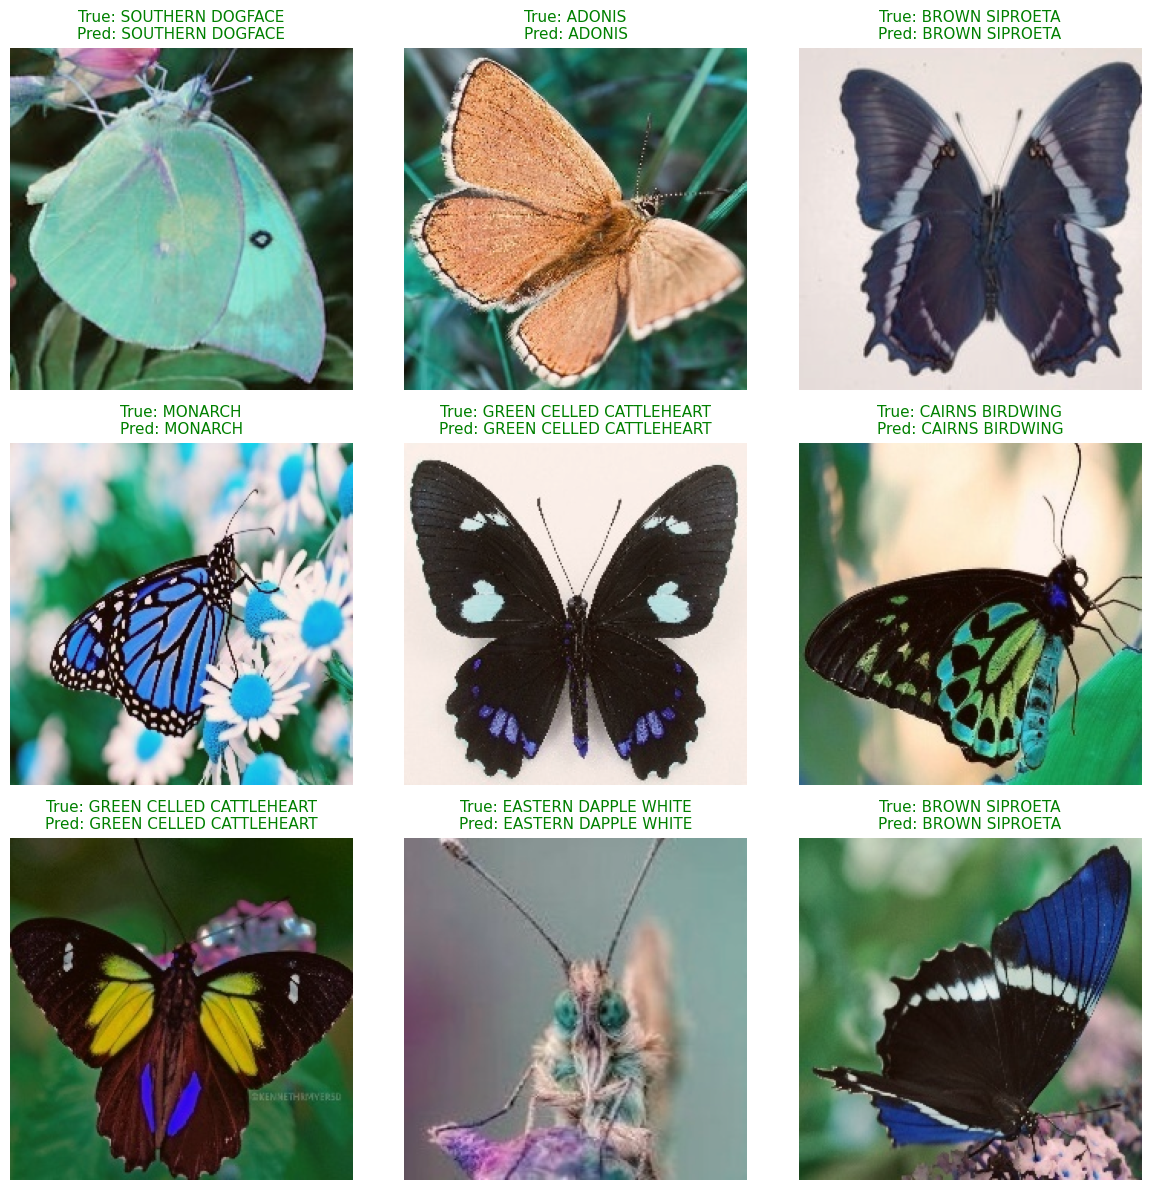

In [9]:
# Mengambil satu batch data dari val_generator
val_generator.reset()
val_images, val_labels = next(iter(val_generator))

# Melakukan prediksi pada batch tersebut
val_preds = model.predict(val_images, verbose=0)

true_classes = np.argmax(val_labels, axis=1) if val_labels.ndim > 1 else val_labels
pred_classes = np.argmax(val_preds, axis=1)

# Membuat visualisasi grid 3x3 untuk 9 gambar pertama
plt.figure(figsize=(12, 12))
for i in range(min(9, len(val_images))):
    plt.subplot(3, 3, i + 1)
    
    # Membalikkan efek preprocess_input ResNet50 untuk visualisasi matplotlib
    img = val_images[i].copy()
    img = img - img.min()
    if img.max() != 0:
        img = img / img.max()
    
    plt.imshow(img)
    
    true_label = class_names[true_classes[i]]
    pred_label = class_names[pred_classes[i]]
    
    # Teks berwarna hijau jika prediksi benar, merah jika salah
    text_color = 'green' if true_label == pred_label else 'red'
    
    plt.title(f"True: {true_label}\nPred: {pred_label}", color=text_color, fontsize=11)
    plt.axis('off')

plt.tight_layout()
plt.show()

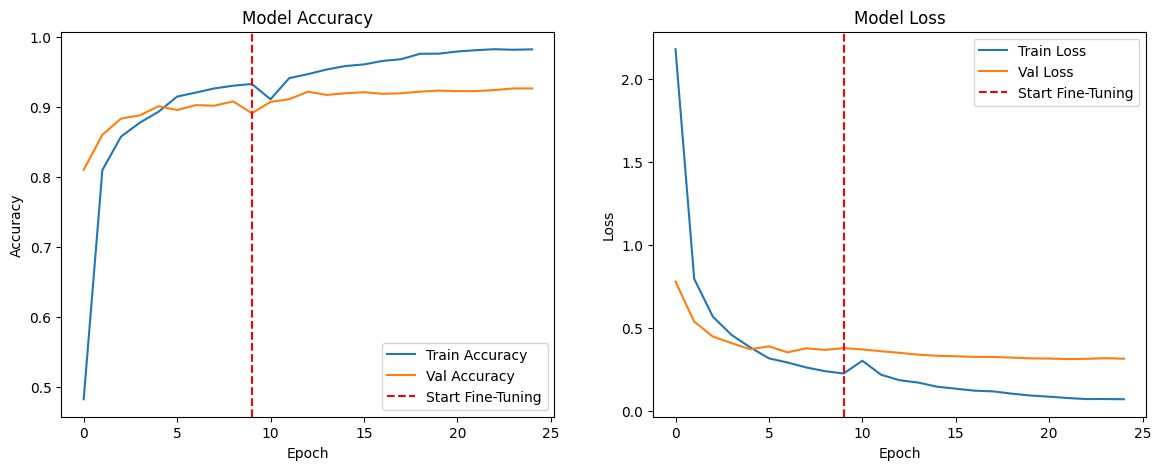

In [7]:
# Menggabungkan history dari Phase 1 dan Phase 2
acc = history1.history['accuracy'] + history2.history['accuracy']
val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']
loss = history1.history['loss'] + history2.history['loss']
val_loss = history1.history['val_loss'] + history2.history['val_loss']

# Menentukan titik potong transisi antara Phase 1 dan Phase 2
initial_epochs = len(history1.history['accuracy'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Akurasi
axes[0].plot(acc, label='Train Accuracy')
axes[0].plot(val_acc, label='Val Accuracy')
axes[0].axvline(x=initial_epochs-1, color='r', linestyle='--', label='Start Fine-Tuning')
axes[0].set_title('Model Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

# Plot Loss
axes[1].plot(loss, label='Train Loss')
axes[1].plot(val_loss, label='Val Loss')
axes[1].axvline(x=initial_epochs-1, color='r', linestyle='--', label='Start Fine-Tuning')
axes[1].set_title('Model Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.show()

Melakukan prediksi pada data validasi untuk evaluasi matriks...
41/41 ━━━━━━━━━━━━━━━━━━━━ 12s 203ms/step

📊 Classification Report:
                           precision    recall  f1-score   support

                   ADONIS       0.90      0.95      0.92        19
AFRICAN GIANT SWALLOWTAIL       1.00      1.00      1.00        17
           AMERICAN SNOOT       1.00      1.00      1.00        16
                    AN 88       1.00      1.00      1.00        17
                  APPOLLO       0.87      0.93      0.90        14
                    ATALA       1.00      1.00      1.00        23
 BANDED ORANGE HELICONIAN       1.00      0.89      0.94        19
           BANDED PEACOCK       0.93      0.88      0.90        16
            BECKERS WHITE       0.93      0.81      0.87        16
         BLACK HAIRSTREAK       1.00      0.93      0.96        27
              BLUE MORPHO       0.88      0.70      0.78        10
        BLUE SPOTTED CROW       0.94      0.94      0.94       

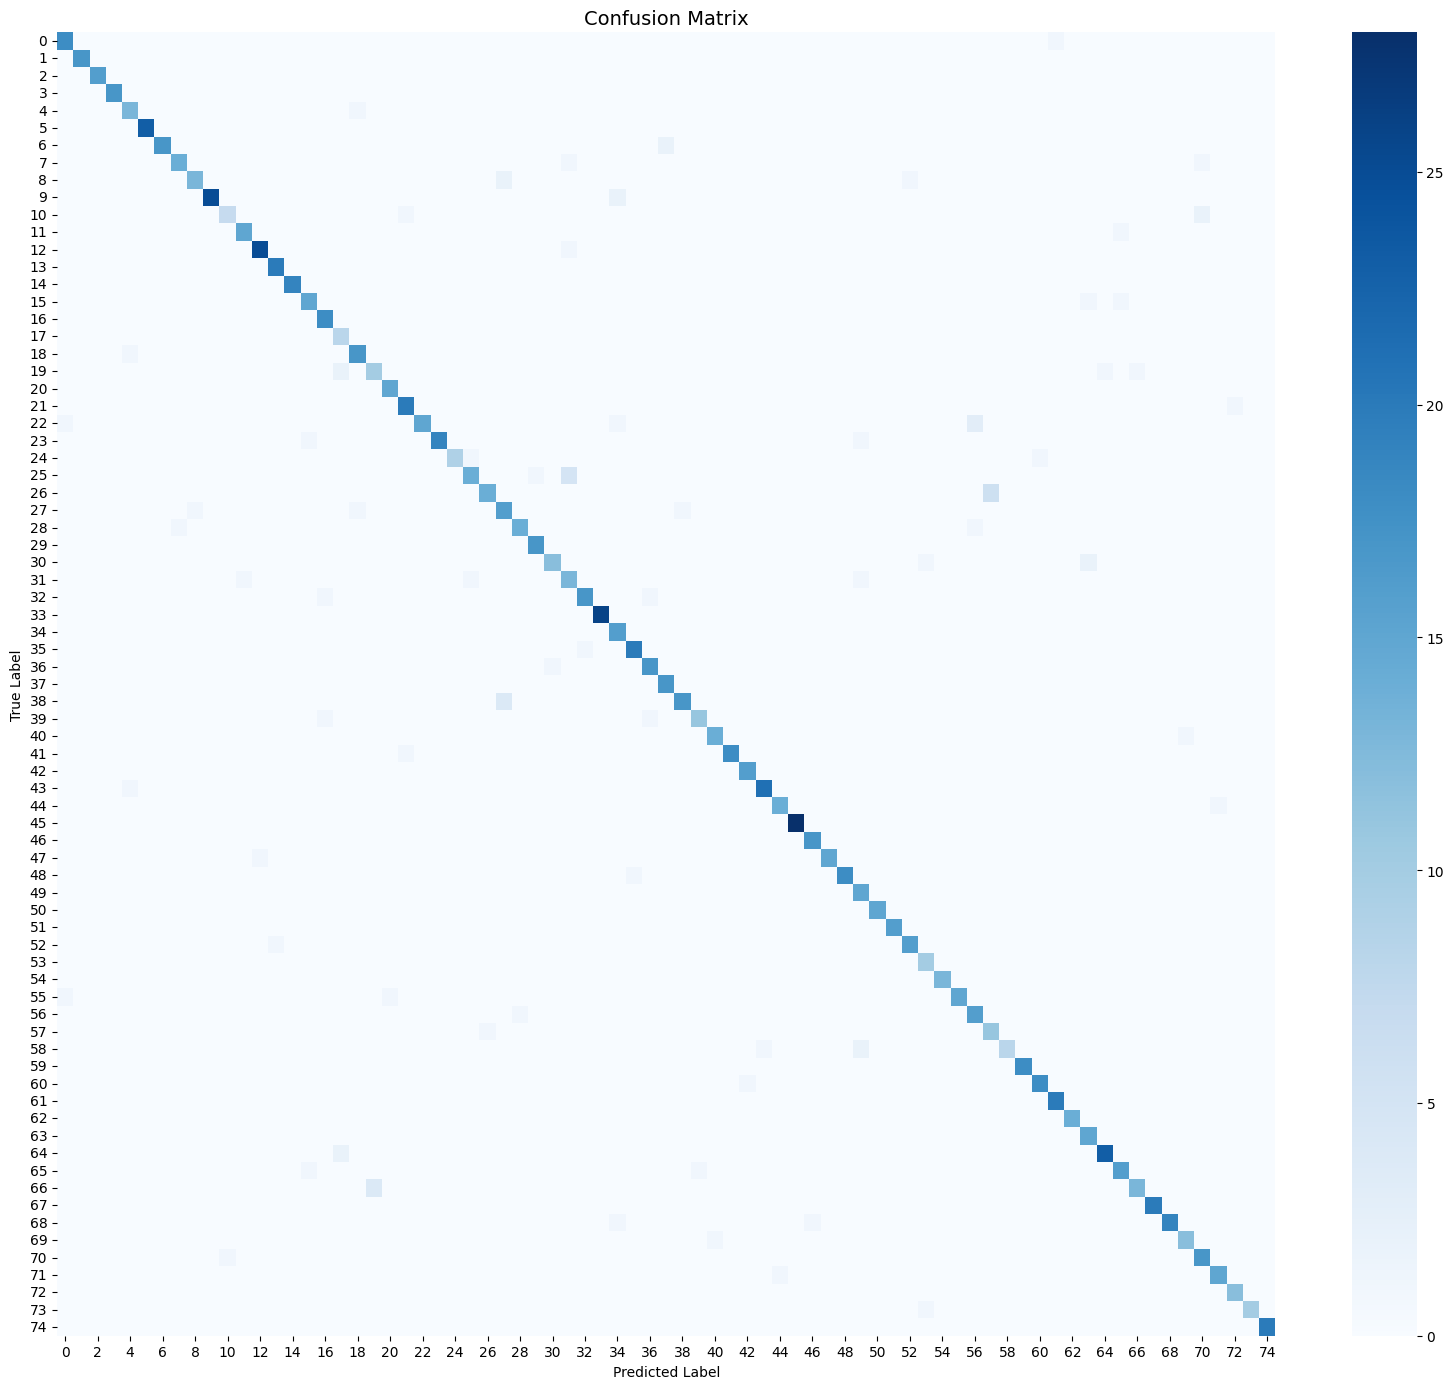

In [8]:
print("Melakukan prediksi pada data validasi untuk evaluasi matriks...")
val_generator.reset()
y_pred_probs = model.predict(val_generator, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = val_generator.classes

print("\n📊 Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(16, 14))
sns.heatmap(cm, annot=False, fmt='d', cmap='Blues')
plt.title('Confusion Matrix', fontsize=14)
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

In [10]:
model.save('butterfly_resnet50_final.keras')

with open('class_indices.json', 'w') as f:
    json.dump(train_generator.class_indices, f)

size = os.path.getsize('butterfly_resnet50_final.keras') / (1024 * 1024)
print(f"✅ Model berhasil tersimpan! Ukuran file: {size:.2f} MB")

✅ Model berhasil tersimpan! Ukuran file: 226.21 MB
